# 03 · Residuos y depreciación

Entradas: `data/autos_clean.csv`, `data/predicciones_test.csv` (del notebook 02) y
`data/autos_raw.csv` (solo para título y URL de los avisos a revisar).

Responde las dos partes de la propuesta que el RMSE no contesta:

1. **¿Qué avisos se alejan mucho del precio que predice el modelo?** (pregunta principal, 2.ª mitad)
2. **¿Cuánto valor pierde un auto por año y por kilómetro, y cambia según la marca?** (secundaria)

Modelo: el mejor del notebook 02 (Ridge, umbral 2, sin interacción, α = 1).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
import cloudpickle
import preparar
from preparar import Preparar, COLS, CAT_TITULO
cloudpickle.register_pickle_by_value(preparar)

DATA, FIGS = Path("../data"), Path("figuras")
SEMILLA = 42
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#5f5e58", "#e4e3dd"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10,
})

df = pd.read_csv(DATA / "autos_clean.csv")
df[CAT_TITULO] = df[CAT_TITULO].astype("string").fillna("sin_dato")
pred = pd.read_csv(DATA / "predicciones_test.csv")
raw = pd.read_csv(DATA / "autos_raw.csv", usecols=["item_id", "titulo", "url"])
pred = pred.merge(raw, on="item_id", how="left")
print(f"Avisos de test con predicción: {len(pred)}")

Avisos de test con predicción: 3386


## Parte 1 · Avisos fuera de mercado

`residuo = log(precio publicado) − log(precio predicho)`. Como está en log,
`exp(residuo) − 1` es **cuánto más caro (o barato) que lo predicho** está el aviso.

Son residuos de **test**: el modelo no vio esos avisos al ajustarse, así que un residuo grande
no es un artefacto de sobreajuste.

In [2]:
pred["desvio_%"] = (np.exp(pred["residuo"]) - 1) * 100
p05, p95 = pred["residuo"].quantile([0.05, 0.95])
print(f"Mediana del residuo: {pred['residuo'].median():+.3f}  (≈ 0: el modelo no está corrido)")
print(f"Percentil 5:  {p05:+.3f} → {(np.exp(p05)-1)*100:+.0f} % respecto de lo predicho")
print(f"Percentil 95: {p95:+.3f} → {(np.exp(p95)-1)*100:+.0f} % respecto de lo predicho")
print(f"Mitad de los avisos a menos de ±{pred['desvio_%'].abs().median():.1f} % de lo predicho")

Mediana del residuo: -0.007  (≈ 0: el modelo no está corrido)
Percentil 5:  -0.339 → -29 % respecto de lo predicho
Percentil 95: +0.323 → +38 % respecto de lo predicho
Mitad de los avisos a menos de ±10.3 % de lo predicho


**Criterio:** un aviso está *fuera de mercado* si su residuo cae fuera del intervalo entre el
percentil 5 y el 95 de los residuos de test. Es un criterio relativo (siempre marca ~10 %);
lo que importa es **qué hay** en esas colas, y eso se revisa a mano abajo.

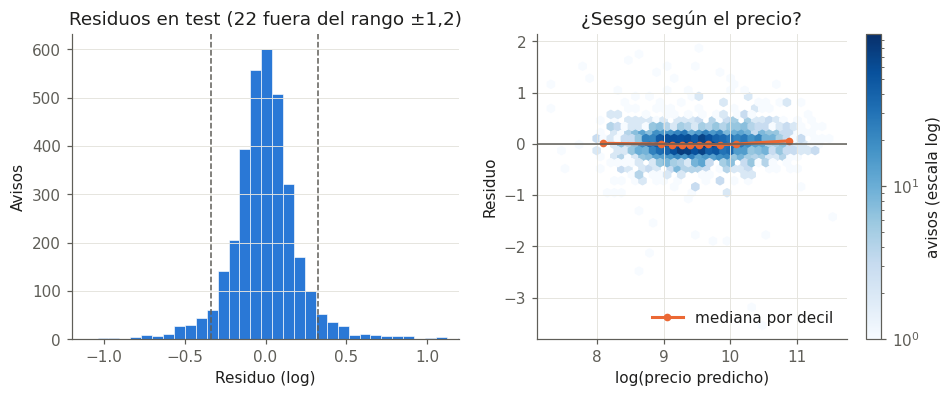

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(pred["residuo"], bins=80, color=SERIES[0], edgecolor="white", linewidth=0.4)
for q in (p05, p95):
    ax[0].axvline(q, color=TINTA_2, linestyle="--", linewidth=1)
fuera = (pred["residuo"].abs() > 1.2).sum()
ax[0].set_xlim(-1.2, 1.2)
ax[0].set(xlabel="Residuo (log)", ylabel="Avisos",
          title=f"Residuos en test ({fuera} fuera del rango ±1,2)")
ax[0].grid(axis="x", visible=False)

pl = np.log(pred["pred_usd"])
hb = ax[1].hexbin(pl, pred["residuo"], gridsize=40, cmap="Blues", mincnt=1, bins="log")
dec = pd.qcut(pl, 10)
tend = pred.groupby(dec, observed=True)["residuo"].median()
ax[1].plot([iv.mid for iv in tend.index], tend.values, color=SERIES[1], marker="o", markersize=4,
           label="mediana por decil")
ax[1].axhline(0, color=TINTA_2, linewidth=1)
ax[1].set(xlabel="log(precio predicho)", ylabel="Residuo", title="¿Sesgo según el precio?")
ax[1].legend(frameon=False, loc="lower right")
fig.colorbar(hb, ax=ax[1], label="avisos (escala log)")
fig.savefig(FIGS / "04_residuos.png")
plt.show()

### ¿El modelo se equivoca parejo?

In [4]:
pred["decil_pred"] = pd.qcut(pred["pred_usd"], 10, labels=False) + 1
sesgo_dec = pred.groupby("decil_pred").agg(
    precio_predicho_mediano=("pred_usd", "median"),
    residuo_mediano=("residuo", "median"),
    error_abs_mediano_pct=("desvio_%", lambda s: s.abs().median()),
).round(3)
sesgo_vend = pred.groupby("tipo_vendedor").agg(
    avisos=("residuo", "size"), residuo_mediano=("residuo", "median"),
    error_abs_mediano_pct=("desvio_%", lambda s: s.abs().median()),
).round(3)
display(sesgo_dec)
display(sesgo_vend)

,precio_predicho_mediano,residuo_mediano,error_abs_mediano_pct
decil_pred,,,
1,5957.0,0.009,14.245
2,7882.0,-0.003,10.537
3,9278.0,-0.015,9.087
4,10614.0,-0.026,9.916
5,12046.0,-0.020,8.509
6,13885.0,-0.014,8.974
7,15707.0,-0.009,9.112
8,18646.0,-0.020,9.334
9,23501.0,-0.004,12.014


,avisos,residuo_mediano,error_abs_mediano_pct
tipo_vendedor,,,
concesionaria,1641,-0.015,9.661
desconocido,10,-0.154,20.081
particular,1735,0.005,10.678


### Los extremos, para revisar a mano

Se guardan los 20 avisos más por debajo y los 20 más por encima en `data/extremos_revisar.csv`,
con una columna `motivo` vacía para que el grupo la complete abriendo cada aviso. Categorías sugeridas:

- `error_carga` (precio o km mal cargados: cuota, precio en otra moneda, un cero de más);
- `version_no_vista` (versión/equipamiento que el modelo no distingue: blindado, edición especial, motor más grande);
- `estado` (chocado, para repuestos, recién restaurado);
- `oportunidad` / `caro` (no se encuentra explicación en el aviso).

In [5]:
cols = ["item_id", "titulo", "anio", "km", "tipo_vendedor", "precio_usd", "pred_usd", "desvio_%", "url"]
abajo = pred.nsmallest(20, "residuo")[cols].assign(lado="muy por debajo")
arriba = pred.nlargest(20, "residuo")[cols].assign(lado="muy por encima")
extremos = pd.concat([abajo, arriba]).assign(motivo="")
extremos["desvio_%"] = extremos["desvio_%"].round(0)
extremos.to_csv(DATA / "extremos_revisar.csv", index=False)
with pd.option_context("display.max_colwidth", 45):
    display(extremos.drop(columns=["url", "item_id", "motivo"]))

,titulo,anio,km,tipo_vendedor,precio_usd,pred_usd,desvio_%,lado
3353,Volkswagen E-up! 2025 0.0 E-up! At,2025,1000,particular,1000.000000,34575.0,-97.0,muy por debajo
3058,Toyota Hilux Sw4 2018 2.8 D.cab. T.dsl Sr...,2018,170000,particular,1179.977643,30147.0,-96.0,muy por debajo
2886,Chevrolet S-10 1998 Cabina Simple,1998,190000,particular,500.000000,5591.0,-91.0,muy por debajo
3303,Peugeot 504 2001 Camioneta,2001,1000000,particular,745.249037,6363.0,-88.0,muy por debajo
3226,Fiat Cinquecento 2027 1.0,2027,11111,particular,3204.570861,20850.0,-85.0,muy por debajo
3350,Zontes U1 2025 200,2025,13000,desconocido,2732.579804,16924.0,-84.0,muy por debajo
2882,Opel Olimpia 2026 1959,2026,4,particular,6600.000000,37601.0,-82.0,muy por debajo
3310,Nissan Sunny 2026 B 12,2026,338000,particular,2300.000000,12961.0,-82.0,muy por debajo
3304,Peugeot 504 2001 2.0 Pick Up G,2001,300000,particular,1490.498075,6988.0,-79.0,muy por debajo
2751,Porsche Cayenne 2012 3.0 S Hybrid 380cv T...,2012,245000,concesionaria,23000.000000,99706.0,-77.0,muy por debajo


## Parte 2 · Depreciación

### 2.1 Pendientes del modelo elegido

Se reajusta el mejor pipeline sobre **train** (mismo split del notebook 02) y se leen sus coeficientes.
Las numéricas entraron estandarizadas: `pendiente_por_unidad` las devuelve a años y a log(km).

- Año: `1 − exp(β_antigüedad)` = **% del precio que se pierde por cada año**, a km constantes.
- Km: con log(km), β es una **elasticidad**: 10 % más km → precio × `1,1^β`.
- Vendedor: diferencia entre los coeficientes de concesionaria y particular, en %.

In [6]:
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_tr, _ = next(split.split(df, groups=df["grupo_gemelo"]))
train = df.iloc[idx_tr].reset_index(drop=True)
assert len(train) == 13507, "el split no coincide con el del notebook 02"
X_tr, y_tr, g_tr = train[COLS], train["log_precio"].to_numpy(), train["grupo_gemelo"]

def modelo(**kw):
    return Pipeline([("prep", Preparar(umbral=2, **kw)), ("reg", Ridge(alpha=1.0))])

m0 = modelo(interaccion=False).fit(X_tr, y_tr)
prep, coef = m0.named_steps["prep"], m0.named_steps["reg"].coef_
pend = prep.pendiente_por_unidad(coef)
coef_nom = dict(zip(prep.nombres(), coef))

b_anio, b_km = pend["antiguedad"], pend["log_km"]
vend = coef_nom["tipo_vendedor_concesionaria"] - coef_nom["tipo_vendedor_particular"]
print(f"Por año:  pierde {(1 - np.exp(b_anio)) * 100:.1f} % del precio (a km, marca y modelo constantes)")
print(f"Por km:   elasticidad {b_km:.3f} → 10 % más km = {(1.1 ** b_km - 1) * 100:+.1f} % de precio;"
      f" duplicar los km = {(2 ** b_km - 1) * 100:+.1f} %")
print(f"Concesionaria vs particular, mismo auto: {(np.exp(vend) - 1) * 100:+.1f} %")

Por año:  pierde 4.5 % del precio (a km, marca y modelo constantes)
Por km:   elasticidad -0.058 → 10 % más km = -0.6 % de precio; duplicar los km = -3.9 %
Concesionaria vs particular, mismo auto: +3.7 %


### 2.2 ¿La depreciación cambia según la marca?

En el notebook 02 la interacción antigüedad × marca **empeoraba** la validación con umbral 2:
le daba una pendiente propia a marcas con 2 o 3 avisos, y eso es ruido. Acá se prueba la versión
razonable: **pendiente propia solo para las marcas con al menos 300 avisos en train**; el resto usa
la pendiente común.

Primero, ¿mejora la predicción? (mismo K-fold agrupado del notebook 02)

In [7]:
UMBRAL_MARCA = 300
cv = GroupKFold(n_splits=5)
comp = {}
for nombre, kw in {"sin interacción": dict(interaccion=False),
                   f"pendiente propia (marcas ≥ {UMBRAL_MARCA})": dict(interaccion=True, umbral_interaccion=UMBRAL_MARCA)}.items():
    s = -cross_val_score(modelo(**kw), X_tr, y_tr, groups=g_tr, cv=cv,
                         scoring="neg_root_mean_squared_error", n_jobs=-1)
    comp[nombre] = {"RMSE_log CV": s.mean(), "desvío entre folds": s.std()}
pd.DataFrame(comp).T.round(4)

,RMSE_log CV,desvío entre folds
sin interacción,0.2670,0.0118
pendiente propia (marcas ≥ 300),0.2664,0.0116


Después, las pendientes por marca, con un **intervalo bootstrap** (se remuestrean grupos de gemelos
de train, 200 veces) para saber si las diferencias entre marcas son reales o ruido de muestreo.

In [8]:
kw_int = dict(interaccion=True, umbral_interaccion=UMBRAL_MARCA)

def pendientes_marca(X, y):
    m = modelo(**kw_int).fit(X, y)
    p = m.named_steps["prep"].pendiente_por_unidad(m.named_steps["reg"].coef_)
    comun = p["antiguedad"]
    return {k.split("×", 1)[1]: comun + v for k, v in p.items() if k.startswith("antiguedad×")} | {"(resto, común)": comun}

punto = pendientes_marca(X_tr, y_tr)

rng = np.random.default_rng(SEMILLA)
grupos = g_tr.unique()
por_grupo = train.groupby("grupo_gemelo").indices
boot = []
for _ in range(200):
    elegidos = rng.choice(grupos, size=len(grupos), replace=True)
    idx = np.concatenate([por_grupo[g] for g in elegidos])
    boot.append(pendientes_marca(X_tr.iloc[idx], y_tr[idx]))
boot = pd.DataFrame(boot)

pct = lambda b: (1 - np.exp(b)) * 100   # pendiente en log → % que pierde por año
n_tr = train["marca"].value_counts()
dep = pd.DataFrame({
    "avisos_train": [n_tr.get(m, np.nan) for m in punto],
    "pierde_%_año": [pct(punto[m]) for m in punto],
    "IC95_bajo": [pct(boot[m].quantile(0.975)) for m in punto],
    "IC95_alto": [pct(boot[m].quantile(0.025)) for m in punto],
}, index=list(punto)).sort_values("pierde_%_año").round(2)
dep

,avisos_train,pierde_%_año,IC95_bajo,IC95_alto
Suzuki,884.0,3.54,3.12,3.97
Citroën,523.0,3.79,3.48,4.21
Toyota,467.0,3.96,3.70,4.58
Fiat,835.0,4.10,3.70,4.39
Volkswagen,1713.0,4.17,3.78,4.60
Chevrolet,1814.0,4.39,4.09,4.70
BMW,369.0,4.39,3.28,5.40
Renault,1054.0,4.59,4.10,4.92
Peugeot,1036.0,4.77,4.21,5.21
Mercedes-Benz,312.0,4.82,4.19,5.56


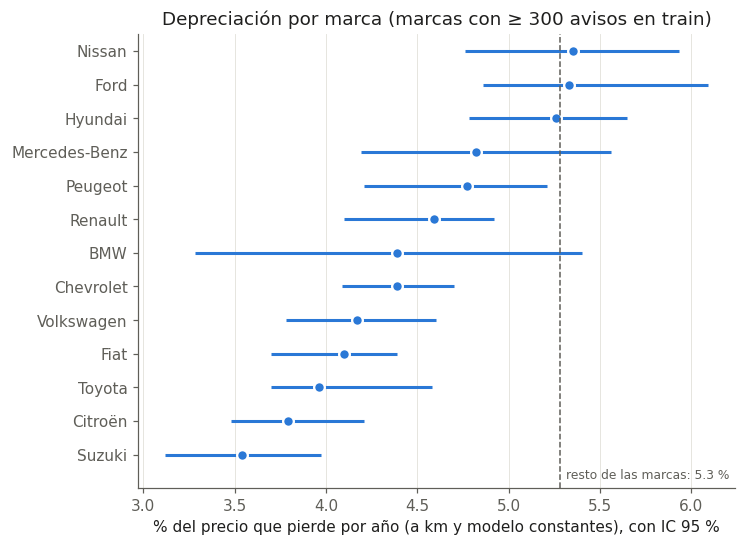

In [9]:
d = dep.drop(index="(resto, común)")
comun = dep.loc["(resto, común)", "pierde_%_año"]
fig, ax = plt.subplots(figsize=(7, 0.32 * len(d) + 1.2))
y = np.arange(len(d))
ax.hlines(y, d["IC95_bajo"], d["IC95_alto"], color=SERIES[0], linewidth=2)
ax.plot(d["pierde_%_año"], y, "o", color=SERIES[0], markersize=7,
        markeredgecolor="white", markeredgewidth=1.5)
ax.axvline(comun, color=TINTA_2, linestyle="--", linewidth=1)
ax.annotate(f"resto de las marcas: {comun:.1f} %", (comun, -0.6), xytext=(4, 0),
            textcoords="offset points", fontsize=8, color=TINTA_2, va="center")
ax.set_ylim(-1, len(d) - 0.5)
ax.set_yticks(y, d.index)
ax.set(xlabel="% del precio que pierde por año (a km y modelo constantes), con IC 95 %",
       title=f"Depreciación por marca (marcas con ≥ {UMBRAL_MARCA} avisos en train)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "05_depreciacion_marca_ic.png")
plt.show()

## Para el informe

Completar con los números de arriba una vez revisados los extremos:

- **Fuera de mercado:** la mitad de los avisos está a menos de ±X % de lo predicho; el 10 % más
  alejado está a más de −Y % / +Z %. De los 40 extremos revisados, N eran errores de carga, …
- **Sesgo:** ¿el modelo sobrevalúa los autos baratos y subvalúa los caros? (tabla por decil).
- **Depreciación:** un auto pierde ~X % por año y duplicar los km le resta ~Y %.
- **Por marca:** la pendiente propia por marca mejora / no mejora la validación; las marcas cuyos
  intervalos no se solapan con el resto son …
- **Concesionaria vs particular:** por el mismo auto, la concesionaria pide ~X % más / menos.